# Topic 22e - From patterns to insights

The main lesson stated three checks for a candidate finding: sample size, shared cause, interesting vs. important. This notebook applies them to two real anomaly events hiding in the air-quality data, and to a set of candidate findings you have to accept or reject.

Work through it after reading section 6 of the [main lesson](topic22_exploratory_data_analysis.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "exploratory_data_analysis" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "air_quality_readings.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find air_quality_readings.csv. Looked in: " +
        ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette (Topic 21) - fixed hue order, never cycled, so a category
# keeps the same colour in every chart it appears in.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"
INK = "#0b0b0b"
STATION_TYPE_COLOR = {
    "Roadside": PALETTE["red"], "Industrial": PALETTE["orange"],
    "Residential": PALETTE["aqua"], "Background": PALETTE["blue"],
}
STATION_TYPE_ORDER = ["Roadside", "Industrial", "Residential", "Background"]

WHO_ANNUAL_GUIDELINE = 5.0   # ug/m3, PM2.5 annual mean
WHO_24H_GUIDELINE = 15.0     # ug/m3, PM2.5 24-hour mean

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/exploratory_data_analysis/data
files:             ['air_quality_readings.csv', 'air_quality_readings_assignment.csv', 'air_quality_stations.csv', 'air_quality_stations_assignment.csv', 'customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
stations = pd.read_csv(DATA_DIR / "air_quality_stations.csv")
readings = pd.read_csv(DATA_DIR / "air_quality_readings.csv", parse_dates=["date"])

aq = readings.merge(stations, on="station_id", how="left", validate="m:1")
aq["month"] = aq["date"].dt.month
aq["is_weekend"] = aq["date"].dt.dayofweek.isin([5, 6])
aq["is_harmattan"] = aq["month"].isin([12, 1, 2])

print(f"Air-quality table: {aq.shape[0]} rows x {aq.shape[1]} columns")
print(f"Stations: {aq['station_id'].nunique()}, dates: {aq['date'].min().date()} to {aq['date'].max().date()}")
print(f"Missing pm2_5 readings: {aq['pm2_5'].isna().sum()}")

Air-quality table: 3285 rows x 14 columns
Stations: 9, dates: 2023-01-01 to 2023-12-31
Missing pm2_5 readings: 7


---

## A mystery: one station, or the whole city?

Back in the main lesson's very first chart, a sharp short spike was visible in the citywide average. Here it is again, isolated and dated.

In [3]:
daily = aq.groupby("date")["pm2_5"].mean()
spike_day = daily.idxmax()
print(f"Citywide daily average peaks on {spike_day.date()}, at {daily.max():.1f} ug/m3")
print(f"(The surrounding days average {daily.drop(spike_day).loc['2023-03-15':'2023-03-29'].mean():.1f}.)")

Citywide daily average peaks on 2023-03-22, at 145.6 ug/m3
(The surrounding days average 49.5.)


Is that a single malfunctioning sensor, or something that actually happened across the city? One groupby answers it.

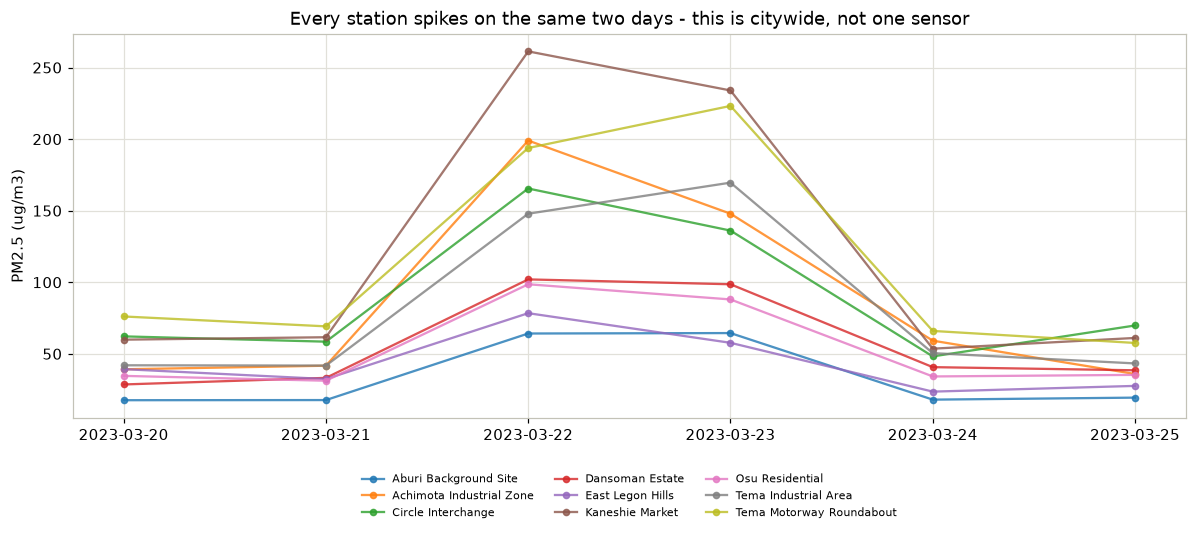

In [4]:
around_spike = aq[aq["date"].between("2023-03-20", "2023-03-25")]
pivot = around_spike.pivot_table(index="date", columns="station_name", values="pm2_5")

fig, ax = plt.subplots(figsize=(11, 5))
for col in pivot.columns:
    ax.plot(pivot.index, pivot[col], marker="o", markersize=4, linewidth=1.5, label=col, alpha=0.8)
ax.set_title("Every station spikes on the same two days - this is citywide, not one sensor")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.legend(frameon=False, fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

Every one of the nine lines rises on the same two days. That rules out a single faulty sensor - whatever happened on 22-23 March affected the whole city at once, which points toward a weather event (a short, severe dust intrusion outside the normal Harmattan window) rather than anything local to one neighbourhood.

---

## A second mystery: the same question, opposite answer

The main lesson's industrial-zone figures hid a second spike, in June - outside Harmattan season entirely. Same investigative method, different answer.

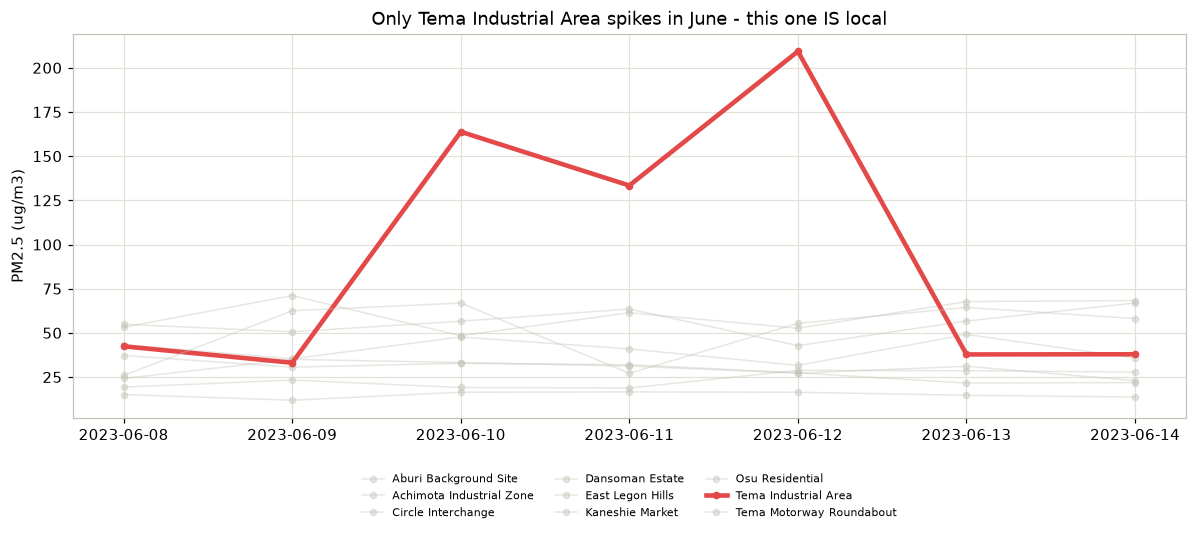

Tema Industrial Area: normal ~41.7 ug/m3, peaks at 209.3 ug/m3 (5.0x) on 10-12 June


In [5]:
june_window = aq[aq["date"].between("2023-06-08", "2023-06-14")]
pivot2 = june_window.pivot_table(index="date", columns="station_name", values="pm2_5")

fig, ax = plt.subplots(figsize=(11, 5))
for col in pivot2.columns:
    style = {"linewidth": 3, "alpha": 1.0} if col == "Tema Industrial Area" else {"linewidth": 1, "alpha": 0.4}
    color = PALETTE["red"] if col == "Tema Industrial Area" else MUTED
    ax.plot(pivot2.index, pivot2[col], marker="o", markersize=4, color=color, label=col, **style)
ax.set_title("Only Tema Industrial Area spikes in June - this one IS local")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.legend(frameon=False, fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

normal = aq[(aq["station_name"] == "Tema Industrial Area") & aq["date"].between("2023-06-01", "2023-06-09")]["pm2_5"].mean()
peak = aq[(aq["station_name"] == "Tema Industrial Area") & aq["date"].between("2023-06-10", "2023-06-12")]["pm2_5"].max()
print(f"Tema Industrial Area: normal ~{normal:.1f} ug/m3, peaks at {peak:.1f} ug/m3 ({peak/normal:.1f}x) on 10-12 June")

Same visual method, opposite conclusion: this spike sits on top of one line, not all nine. That single difference - citywide versus single-station - is usually enough to tell a weather event from an equipment fault or a local incident, before you ever need an external news report to confirm it.

---

## Accept or reject: five candidate findings

A colleague hands you five "findings" from a first pass over this data. Apply the three checks from the main lesson - sample size, shared cause, interesting vs. important - to each, and say which you would actually put in a report.

1. "Aburi Background Site had its single highest reading on a Tuesday - Tuesdays must be worse for air quality."
2. "PM2.5 and PM10 correlate at r = 0.99, so reducing one will reduce the other."
3. "Roadside stations average 63.9 ug/m3 against Background's 17.7 - location matters more than weather."
4. "Industrial stations' NO2 (27.9) is lower than Roadside's (35.2), so industrial activity matters less than traffic."
5. "The two anomaly events in this dataset prove Accra's air quality is getting worse."

In [6]:
# YOUR CODE HERE
# For each of the five, write accept/reject and one sentence of reasoning.

A hint on two of the five: (1) one single data point is never a day-of-week pattern - that is sample size. (5) two specific, dated events are evidence of two events, not of a trend - generalising from them to "getting worse" needs many more years of data than this dataset has.

---
## Where this fits

- [Back to the main lesson](topic22_exploratory_data_analysis.ipynb)
- Previous: [22d - Multivariate exploration](topic22d_multivariate_exploration.ipynb)
- Next: [22f - Writing the wrangling report](topic22f_writing_the_wrangling_report.ipynb)